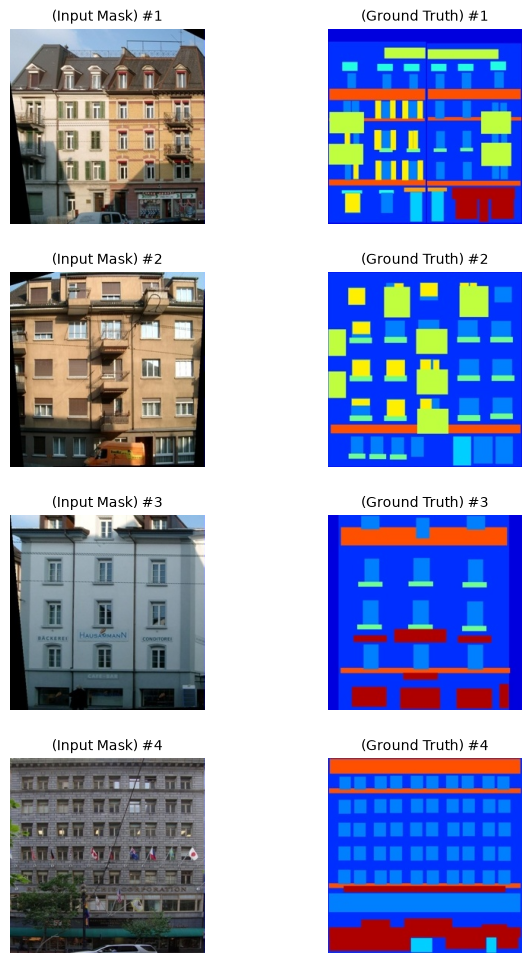

In [45]:
import os
import tarfile
import urllib.request
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as T

DATASET_NAME = "facades"
DATA_DIR = "./datasets"
URL = f"https://efrosgans.eecs.berkeley.edu/pix2pix/datasets/{DATASET_NAME}.tar.gz"

os.makedirs(DATA_DIR, exist_ok=True)
tar_path = os.path.join(DATA_DIR, f"{DATASET_NAME}.tar.gz")
extract_path = os.path.join(DATA_DIR, DATASET_NAME)


def download_progress_hook(block_num, block_size, total_size):
    downloaded = block_num * block_size
    percent = (downloaded / total_size) * 100 if total_size > 0 else 0
    mb_downloaded = downloaded / (1024 * 1024)
    mb_total = total_size / (1024 * 1024)
    
    bar_length = 30
    filled_length = int(bar_length * downloaded // total_size) if total_size > 0 else 0
    bar = "█" * filled_length + "-" * (bar_length - filled_length)
    
    print(f"\r[{bar}] {percent:5.1f}% | {mb_downloaded:5.1f}/{mb_total:5.1f} MB", end="", flush=True)


class Pix2PixDataset(Dataset):
    def __init__(self, root_dir, split="train", transform=None):
        self.split_dir = os.path.join(root_dir, split)
            
        self.image_files = sorted([
            f for f in os.listdir(self.split_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])
        self.transform = transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.split_dir, self.image_files[idx])
        combined_img = Image.open(img_path).convert("RGB")
        
        w, h = combined_img.size
        input_img = combined_img.crop((0, 0, w // 2, h))
        target_img = combined_img.crop((w // 2, 0, w, h))

        if self.transform:
            input_img = self.transform(input_img)
            target_img = self.transform(target_img)

        return input_img, target_img

transform = T.Compose([
    T.Resize((256, 256)),
    T.ToTensor(),
    T.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

train_dataset = Pix2PixDataset(root_dir=extract_path, split="train", transform=transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    pin_memory=torch.cuda.is_available()
)


def denormalize(tensor):
    return (tensor * 0.5 + 0.5).clamp(0, 1)

if __name__ == "__main__":
    inputs, targets = next(iter(train_loader))

    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(8, 12))
    plt.subplots_adjust(wspace=0.05, hspace=0.25)

    for i in range(4):
        inp = denormalize(inputs[i]).permute(1, 2, 0).cpu().numpy()
        tar = denormalize(targets[i]).permute(1, 2, 0).cpu().numpy()

        axes[i, 0].imshow(inp)
        axes[i, 0].set_title(f"(Input Mask) #{i+1}", fontsize=10)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(tar)
        axes[i, 1].set_title(f"(Ground Truth) #{i+1}", fontsize=10)
        axes[i, 1].axis("off")

    plt.show()


In [2]:
import torch.nn as nn

In [7]:
class DownBlock(nn.Module):

    def __init__(self , in_channels , out_channels , add_bn = True):
        super().__init__()

        layers = [
            nn.Conv2d(in_channels , out_channels , 4 , 2 , 1 , bias = not add_bn)
        ]

        if add_bn:
            layers.append(
                nn.BatchNorm2d(out_channels)
            )

        layers.append(
            nn.LeakyReLU(0.2)
        )

        self.block = nn.Sequential(*layers)

    def forward(self , x):
        return self.block(x)

In [26]:
class UpBlock(nn.Module):

    def __init__(self, in_channels , out_channels , use_dropout = False):
        super().__init__()

        layers = [
            nn.ConvTranspose2d(in_channels , out_channels , 4 , 2 , 1 , bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()

        ]

        if use_dropout:
            layers.append(
                nn.Dropout()
            )

        self.block = nn.Sequential(*layers)

    def forward(self , x , skip_input):
        x = self.block(x)
        x = torch.concat([x , skip_input] , dim = 1)


        return x  

In [38]:
class Generator(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        self.d1 = DownBlock(in_channels, 64, add_bn=False)  
        self.d2 = DownBlock(64, 128)                         
        self.d3 = DownBlock(128, 256)                        
        self.d4 = DownBlock(256, 512)                        
        self.d5 = DownBlock(512, 512)                      
        self.d6 = DownBlock(512, 512)                       
        self.d7 = DownBlock(512, 512)                        
        self.d8 = nn.Sequential(                             
            nn.Conv2d(512, 512, kernel_size=4, stride=2, padding=1, bias=True),
            nn.ReLU(inplace=True)
        )

        self.u1 = UpBlock(512, 512, use_dropout=True)       
        self.u2 = UpBlock(1024, 512, use_dropout=True)       
        self.u3 = UpBlock(1024, 512, use_dropout=True)      
        self.u4 = UpBlock(1024, 512)      
        self.u5 = UpBlock(1024, 256)    
        self.u6 = UpBlock(512, 128)       
        self.u7 = UpBlock(256, 64)      
        
        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh()  
        )

    def forward(self, x):
        d1 = self.d1(x)
        d2 = self.d2(d1)
        d3 = self.d3(d2)
        d4 = self.d4(d3)
        d5 = self.d5(d4)
        d6 = self.d6(d5)
        d7 = self.d7(d6)
        d8 = self.d8(d7)

        u1 = self.u1(d8, d7)
        u2 = self.u2(u1, d6)
        u3 = self.u3(u2, d5)
        u4 = self.u4(u3, d4)
        u5 = self.u5(u4, d3)
        u6 = self.u6(u5, d2)
        u7 = self.u7(u6, d1)
        
        return self.final(u7) 

In [39]:
class Discriminator(nn.Module):
    def __init__(self, condition_channels=3, target_channels=3):
        super().__init__()

        in_channels = condition_channels + target_channels

        self.net = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, kernel_size=4, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=1)
        )

    def forward(self, x):
        return self.net(x)

In [40]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

device

'cuda'

In [41]:
G = Generator().to(device)
D = Discriminator().to(device)

In [42]:
optimizerG = torch.optim.Adam(params = G.parameters(),
                            lr= 0.0002 ,
                            betas=(0.5, 0.999))

optimizerD = torch.optim.Adam(params = D.parameters(),
                            lr= 0.0002 ,
                            betas=(0.5, 0.999))


loss_fn_BCE = nn.BCEWithLogitsLoss()
loss_fn_L1 = nn.L1Loss()

Epoch [1/20] Loss D: 0.3044, Loss G: 36.7642


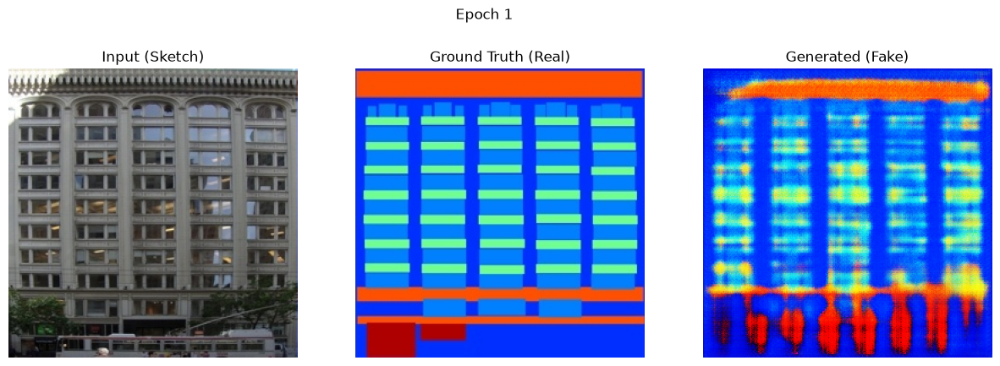

Epoch [2/20] Loss D: 1.4087, Loss G: 31.5759


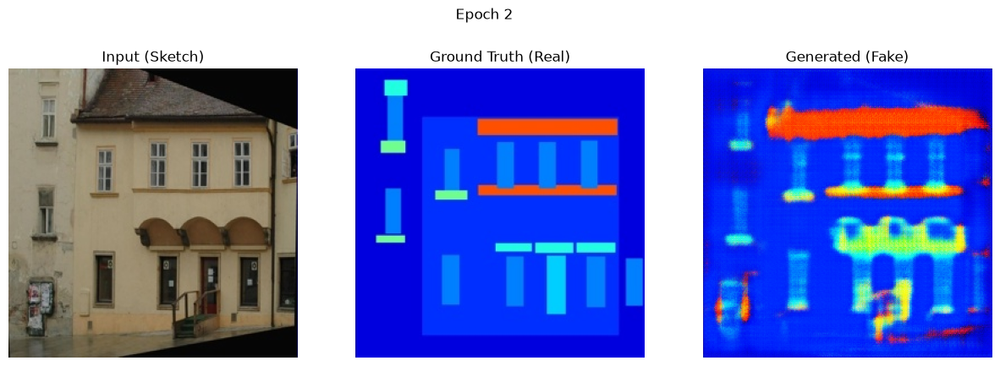

Epoch [3/20] Loss D: 0.2122, Loss G: 40.9053


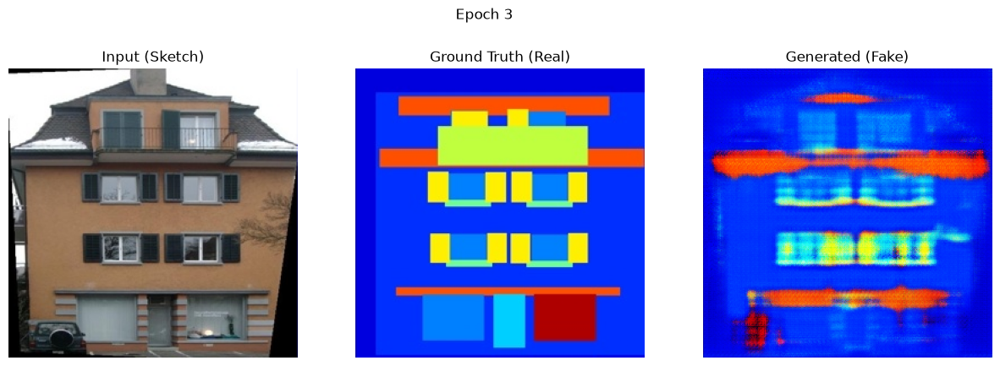

Epoch [4/20] Loss D: 0.1949, Loss G: 33.2777


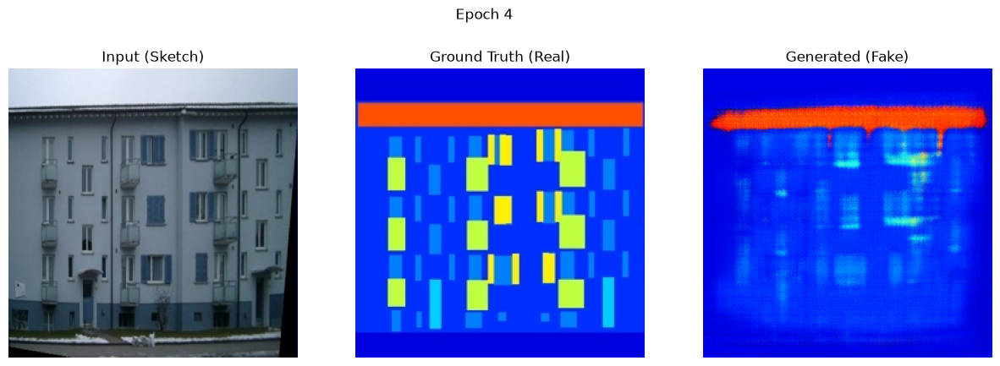

Epoch [5/20] Loss D: 0.3275, Loss G: 43.1840


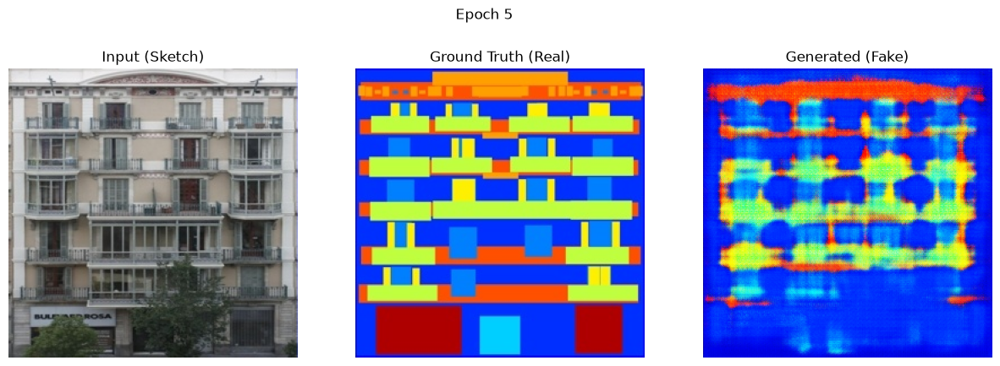

Epoch [6/20] Loss D: 0.6309, Loss G: 29.4779


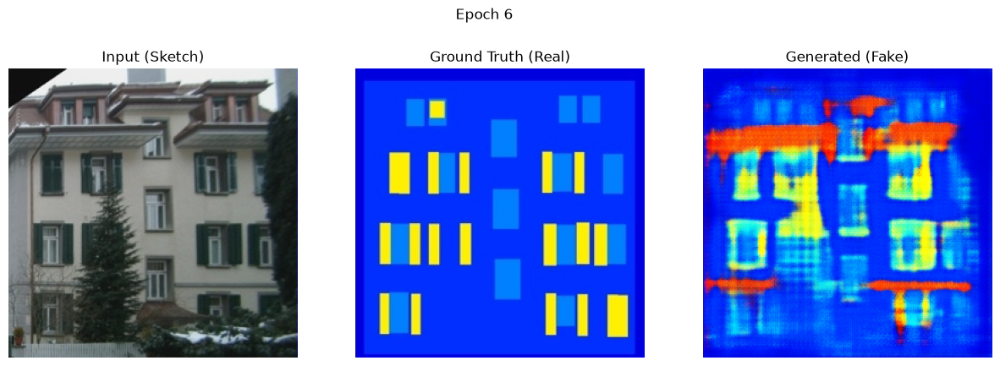

Epoch [7/20] Loss D: 0.2955, Loss G: 40.3398


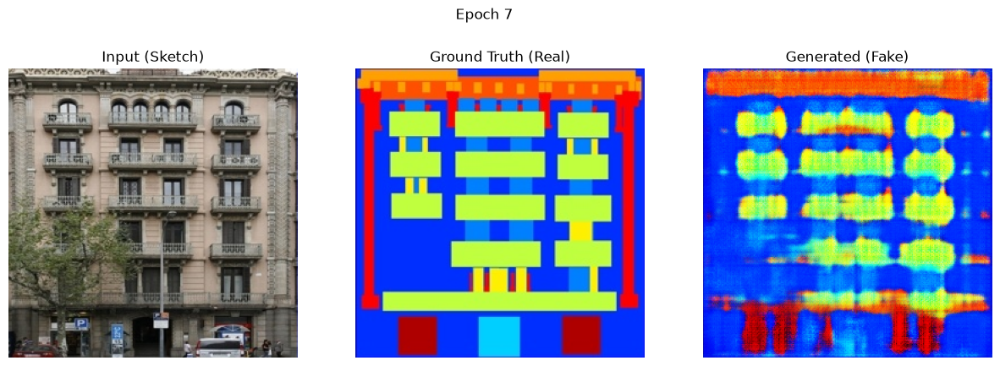

Epoch [8/20] Loss D: 0.2841, Loss G: 41.7612


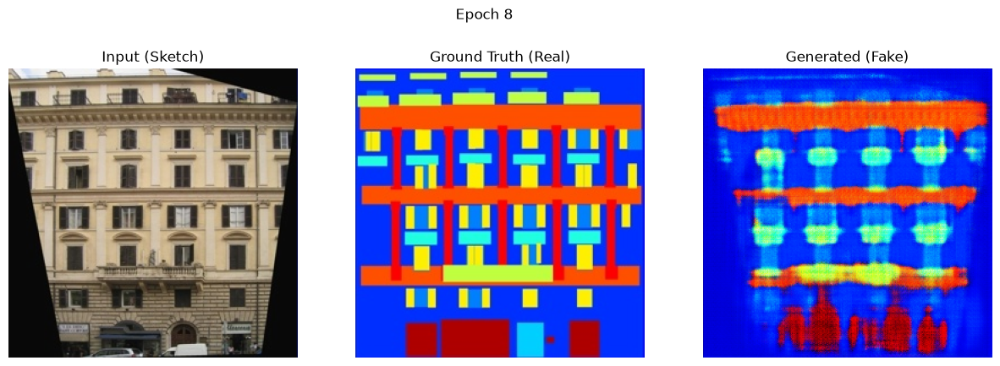

Epoch [9/20] Loss D: 0.2593, Loss G: 32.9084


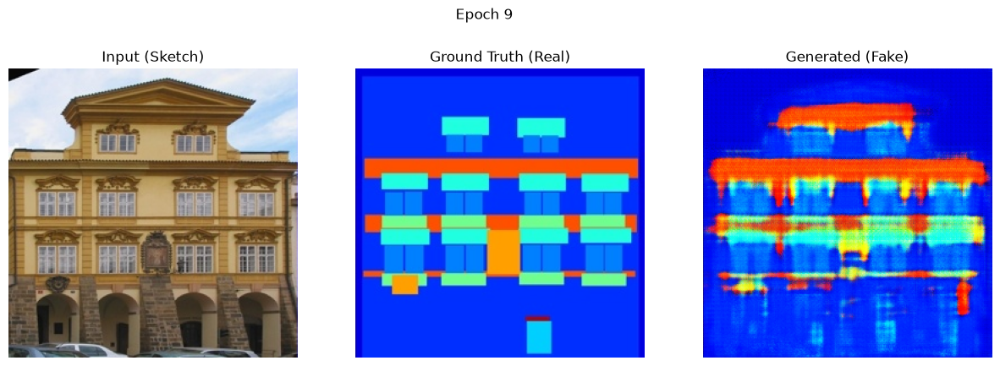

Epoch [10/20] Loss D: 0.6131, Loss G: 28.2271


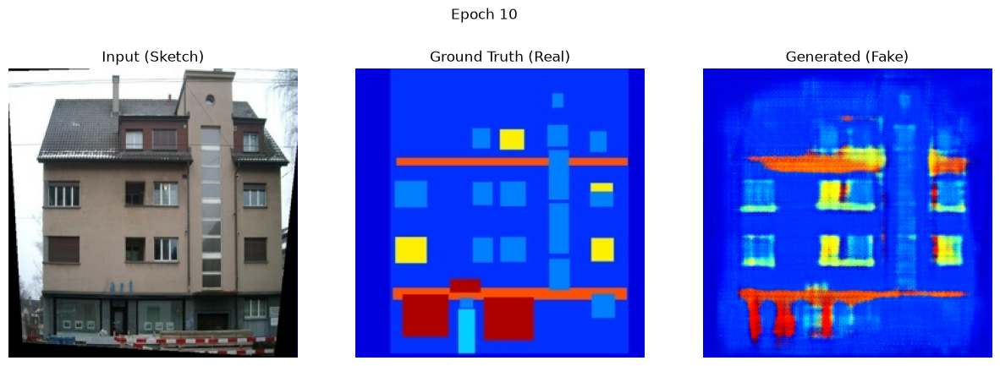

Epoch [11/20] Loss D: 0.2536, Loss G: 28.3958


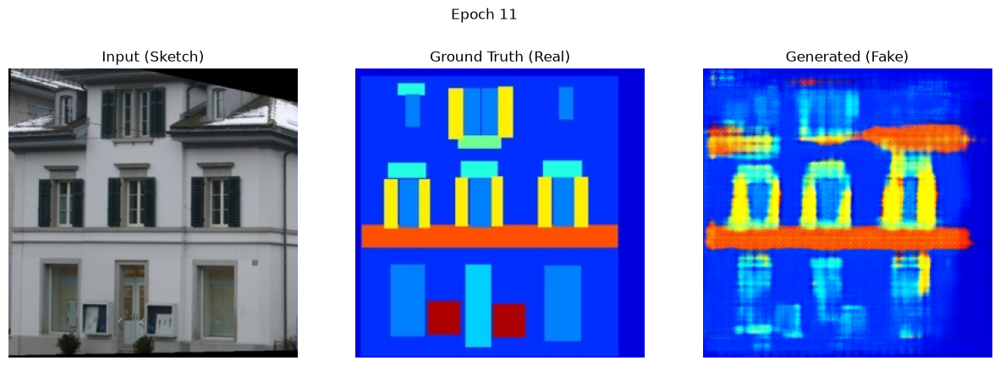

Epoch [12/20] Loss D: 0.3821, Loss G: 38.0444


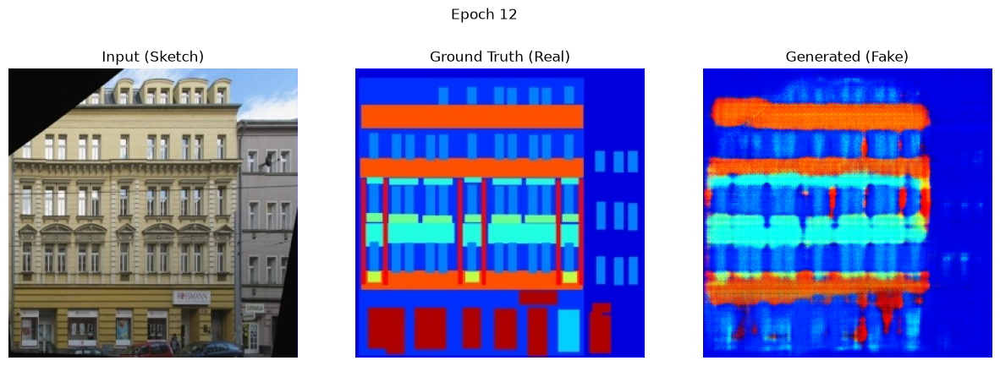

Epoch [13/20] Loss D: 0.2681, Loss G: 26.5475


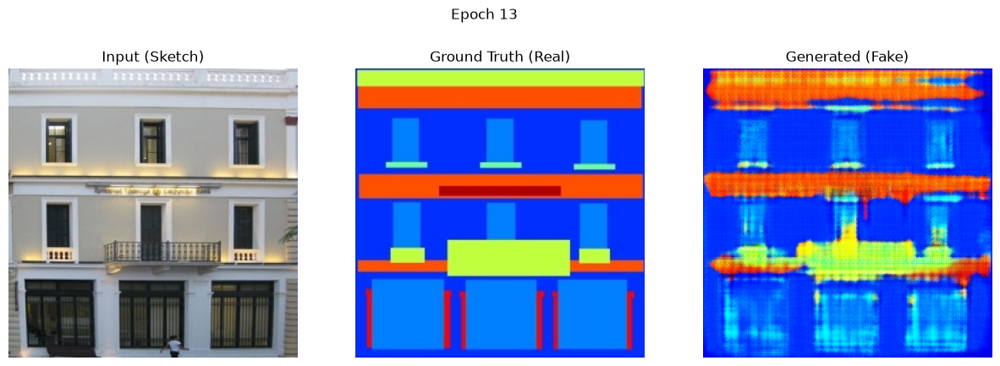

Epoch [14/20] Loss D: 0.2603, Loss G: 25.3401


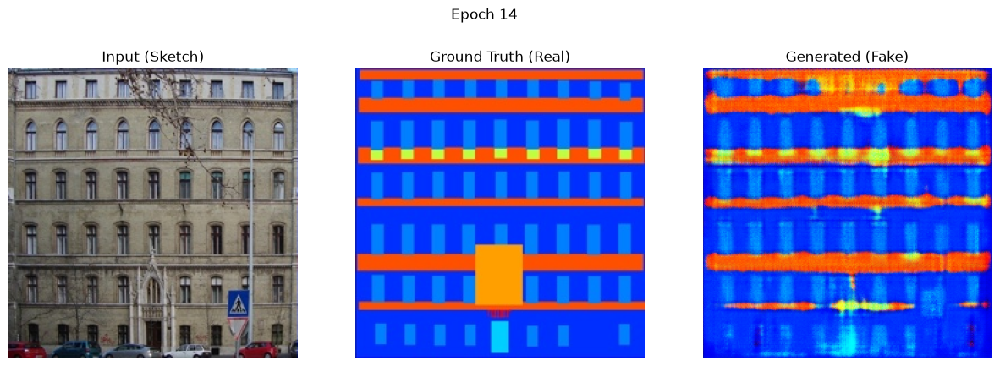

Epoch [15/20] Loss D: 0.3487, Loss G: 26.6967


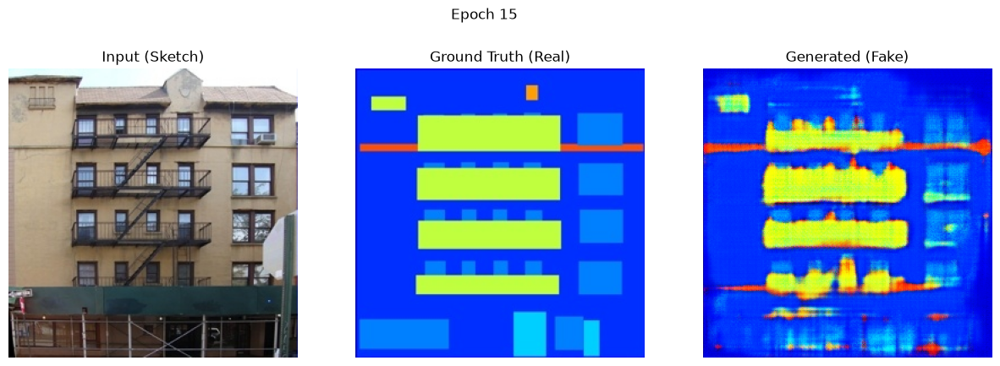

Epoch [16/20] Loss D: 0.2868, Loss G: 24.1302


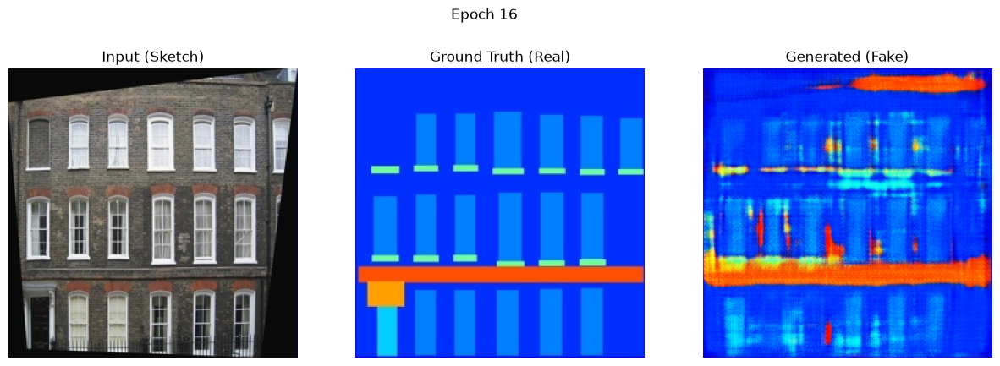

Epoch [17/20] Loss D: 0.2544, Loss G: 28.6971


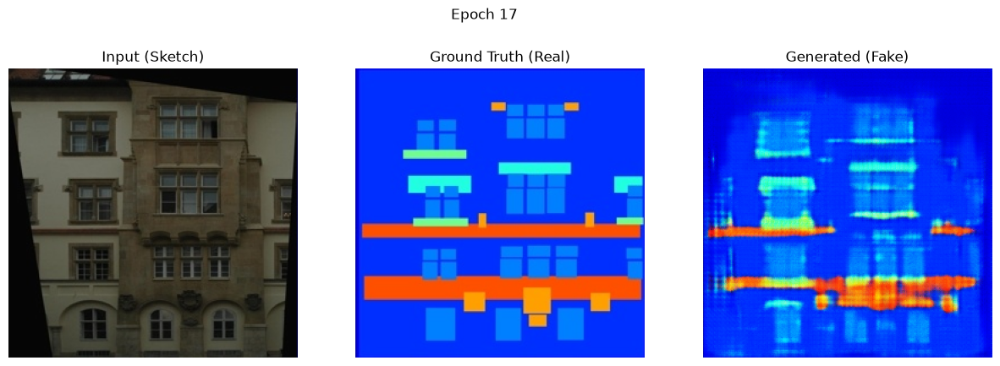

Epoch [18/20] Loss D: 0.4336, Loss G: 23.6355


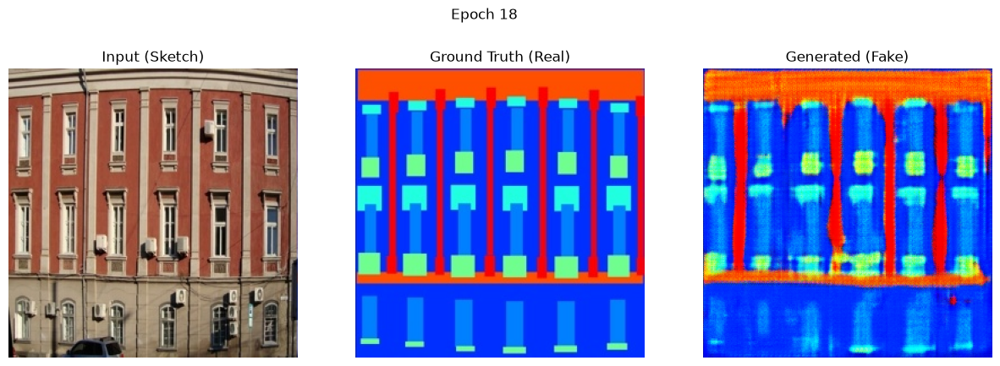

Epoch [19/20] Loss D: 0.4992, Loss G: 20.6832


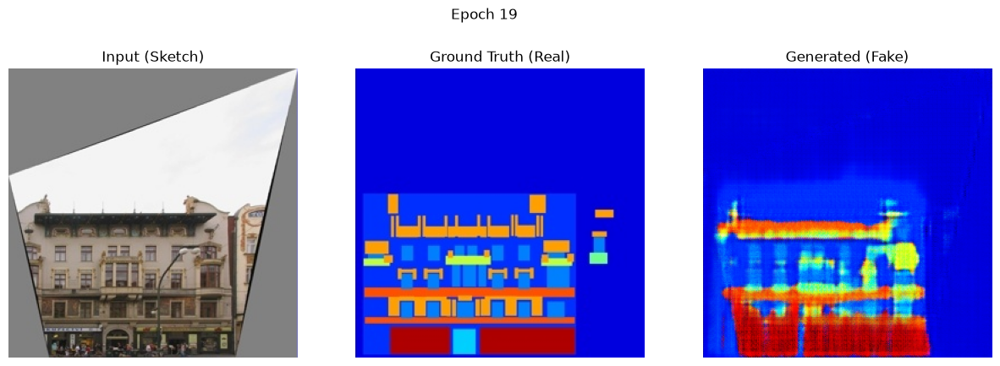

Epoch [20/20] Loss D: 0.2490, Loss G: 22.5558


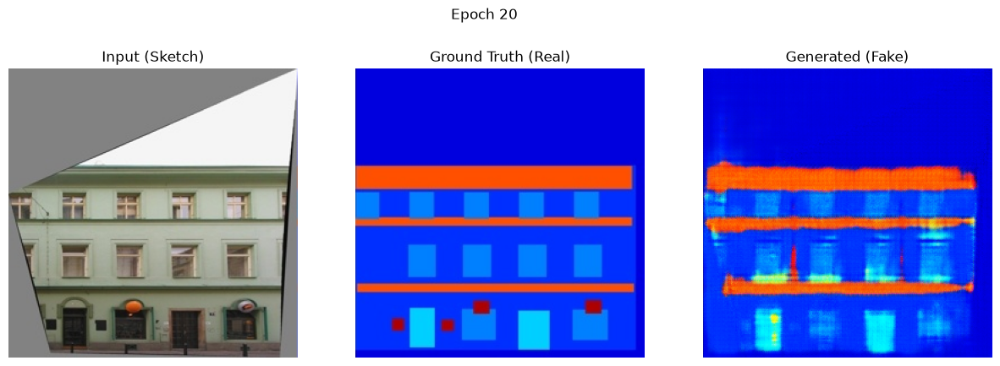

In [ ]:
import matplotlib.pyplot as plt

def show_result(condition, fake, real, epoch):
    condition = (condition[0].cpu().detach().permute(1, 2, 0) + 1) / 2
    fake = (fake[0].cpu().detach().permute(1, 2, 0) + 1) / 2
    real = (real[0].cpu().detach().permute(1, 2, 0) + 1) / 2

    plt.figure(figsize=(15, 5))
    
    display_list = [condition, real, fake]
    title = ['Input (Sketch)', 'Ground Truth (Real)', 'Generated (Fake)']

    for i in range(3):
        plt.subplot(1, 3, i+1)
        plt.title(title[i])
        plt.imshow(display_list[i])
        plt.axis('off')
    
    plt.suptitle(f"Epoch {epoch+1}")
    plt.show()

EPOCHS = 20

for epoch in range(EPOCHS):
    for real_images, y in train_loader:
        real_images, y = real_images.to(device), y.to(device)
        

        optimizerD.zero_grad()
        pred_real = D(torch.concat([real_images, y], dim=1))
        loss_real = loss_fn_BCE(pred_real, torch.full_like(pred_real, 0.9))
        
        fake_images = G(real_images)
        pred_fake = D(torch.concat([real_images, fake_images.detach()], dim=1))
        loss_fake = loss_fn_BCE(pred_fake, torch.zeros_like(pred_fake))
        
        lossD = (loss_real + loss_fake) * 0.5
        lossD.backward()
        optimizerD.step()

        optimizerG.zero_grad()
        pred_G = D(torch.concat([real_images, fake_images], dim=1))
        lossG = loss_fn_BCE(pred_G, torch.ones_like(pred_G)) + 100 * loss_fn_L1(fake_images, y)
        lossG.backward()
        optimizerG.step()

    print(f"Epoch [{epoch+1}/{EPOCHS}] Loss D: {lossD.item():.4f}, Loss G: {lossG.item():.4f}")

    show_result(real_images, fake_images, y, epoch)
